In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

%matplotlib inline

print("Bibliothèques importées avec succès !")

Bibliothèques importées avec succès !


In [6]:
data = pd.read_csv("../Dataset_ProjetIA_food/moroccan_recipes_dataset.csv")

print("Dataset chargé avec succès !")
print("Dimensions :", data.shape)

Dataset chargé avec succès !
Dimensions : (4627, 2)


In [7]:
data_clean = data.copy()

print("Copie créée avec succès !")

Copie créée avec succès !


In [ ]:
#2. Extraire le nom de chaque recette
data_clean['Recipe_Name'] = data_clean['prompt'].str.extract(
    r'Recipe Name\s*:\s*(.*)'
)

data_clean[['Recipe_Name']].head()


,Recipe_Name
0,Duck and prune tagine
1,Potato tagine with baked halloumi
2,Merguez sausages with crispy chickpeas and pre...
3,Chicken tagine casserole
4,Preserved lemons


In [ ]:
#3. Extraire la description des recettes
data_clean['Description'] = data_clean['prompt'].str.extract(
    r'Description\s*:\s*(.*)',
    flags=re.DOTALL
)

data_clean[['Recipe_Name', 'Description']].head()


,Recipe_Name,Description
0,Duck and prune tagine,Duck legs are the ultimate choice for low-and-...
1,Potato tagine with baked halloumi,This North African-inspired potato dish is by ...
2,Merguez sausages with crispy chickpeas and pre...,"Merguez sausages with crispy, roasted chickpea..."
3,Chicken tagine casserole,Enjoy all the rich flavours of a chicken tagin...
4,Preserved lemons,With only two basic ingredients and some imagi...


In [46]:
#4. Extraire les ingrédients
for i in range(3):
    print("RECETTE :", i + 1)
    print(data_clean.loc[i, 'Ingredients'])
    print("\nINSTRUCTIONS :")
    print(data_clean.loc[i, 'completion'])
    print("\n" + "=" * 80 + "\n")



RECETTE : 1
['2 tbsp olive oil', '2 cinnamon sticks', '3 red onions, finely sliced', '5 garlic cloves, finely sliced', '2 tbsp harissa', '4 tbsp ras el hanout', '2 tsp ground ginger', '4 large duck legs', '1 litre chicken stock', '2 x 400g tins chopped tomatoes', '2 preserved lemons', '400g tin chickpeas, drained', '150g pitted kalamata olives', '200g soft pitted prunes']

INSTRUCTIONS :
['Pour the oil into a heavy-based pan or casserole over a medium heat, then add the cinnamon sticks followed by the onions, garlic and a pinch of salt. Cook for about 5 minutes until the onions are just starting to soften, then add the harissa, ras el hanout and ground ginger. Stir for another minute.#', 'Add the duck legs, then cover with the stock and tinned tomatoes. Quarter the preserved lemons and scrape out the flesh, reserving half of it, then finely chop the peel and add the reserved flesh and peel to the pan. Leave to cook over a low heat, uncovered, for 2 hours.', 'Carefully remove the duck l

In [47]:
#5. Nettoyer les noms des recettes
#Nous allons supprimer les espaces inutiles et uniformiser les noms
data_clean['Recipe_Name'] = data_clean['Recipe_Name'].str.strip()

print("Nettoyage des noms terminé !")


Nettoyage des noms terminé !


In [48]:

#6. Supprimer les recettes sans nom
data_clean = data_clean.dropna(subset=['Recipe_Name'])

print("Nombre de recettes après suppression :", len(data_clean))


Nombre de recettes après suppression : 3291


In [49]:
#7. Supprimer les doublons
data_clean = data_clean.drop_duplicates(subset=['Recipe_Name'])

print("Nombre de recettes après suppression des doublons :", len(data_clean))


Nombre de recettes après suppression des doublons : 3291


In [50]:
#8. Réinitialiser les index
data_clean = data_clean.reset_index(drop=True)

data_clean.head()


,prompt,completion,Recipe_Name,Description,Instructions,Instruction_Length,Ingredients
0,Recipe Name : Duck and prune tagine\n Descript...,['Pour the oil into a heavy-based pan or casse...,Duck and prune tagine,Duck legs are the ultimate choice for low-and-...,['Pour the oil into a heavy-based pan or casse...,948,"[2 tbsp olive oil, 2 cinnamon sticks, 3 red on..."
1,Recipe Name : Potato tagine with baked halloum...,['Heat the oven to 180°C fan/gas 6. Heat the o...,Potato tagine with baked halloumi,This North African-inspired potato dish is by ...,['Heat the oven to 180°C fan/gas 6. Heat the o...,737,"[2 tbsp vegetable oil, 2 onions, sliced, 6 gar..."
2,Recipe Name : Merguez sausages with crispy chi...,['Heat the oven to 180°C fan/gas 6. Put the ch...,Merguez sausages with crispy chickpeas and pre...,"Merguez sausages with crispy, roasted chickpea...",['Heat the oven to 180°C fan/gas 6. Put the ch...,904,"[2 x 400g tins chickpeas, drained, 3 tbsp oliv..."
3,Recipe Name : Chicken tagine casserole\n Descr...,['Heat the oven to 180ºC fan/gas 6. Slash the ...,Chicken tagine casserole,Enjoy all the rich flavours of a chicken tagin...,['Heat the oven to 180ºC fan/gas 6. Slash the ...,486,"[8 small free-range chicken thighs, 2 medium r..."
4,Recipe Name : Preserved lemons\n Description :...,['Juice 4 of the lemons and set the juice asid...,Preserved lemons,With only two basic ingredients and some imagi...,['Juice 4 of the lemons and set the juice asid...,828,[12 small unwaxed lemons (about 1kg; see tips)...


In [ ]:
#9. Vérifier les valeurs manquantes après nettoyage
print("Valeurs manquantes :")
print(data_clean.isnull().sum())


Valeurs manquantes :
prompt            0
completion        7
Recipe_Name       0
Description    2273
dtype: int64


In [ ]:
#10. Nettoyer les descriptions
#Nous allons supprimer les espaces inutiles et les caractères de retour à la ligne.

data_clean['Description'] = (
    data_clean['Description']
    .fillna('')
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

data_clean[['Recipe_Name', 'Description']].head()


,Recipe_Name,Description
0,Duck and prune tagine,Duck legs are the ultimate choice for low-and-...
1,Potato tagine with baked halloumi,This North African-inspired potato dish is by ...
2,Merguez sausages with crispy chickpeas and pre...,"Merguez sausages with crispy, roasted chickpea..."
3,Chicken tagine casserole,Enjoy all the rich flavours of a chicken tagin...
4,Preserved lemons,With only two basic ingredients and some imagi...


In [22]:
#11. Nettoyer les instructions de préparation
#La colonne completion contient les étapes de préparation. Nous allons la convertir en texte propre.

data_clean['Instructions'] = (
    data_clean['completion']
    .fillna('')
    .astype(str)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

data_clean[['Recipe_Name', 'Instructions']].head()


,Recipe_Name,Instructions
0,Duck and prune tagine,['Pour the oil into a heavy-based pan or casse...
1,Potato tagine with baked halloumi,['Heat the oven to 180°C fan/gas 6. Heat the o...
2,Merguez sausages with crispy chickpeas and pre...,['Heat the oven to 180°C fan/gas 6. Put the ch...
3,Chicken tagine casserole,['Heat the oven to 180ºC fan/gas 6. Slash the ...
4,Preserved lemons,['Juice 4 of the lemons and set the juice asid...


In [23]:
#12. Afficher la longueur des instructions
#Cette étape permet de connaître la quantité de texte disponible pour chaque recette.


data_clean['Instruction_Length'] = data_clean['Instructions'].str.len()

data_clean['Instruction_Length'].describe()


count    3298.000000
mean      814.022741
std       593.493201
min         0.000000
25%       445.000000
50%       682.000000
75%      1018.000000
max      6413.000000
Name: Instruction_Length, dtype: float64

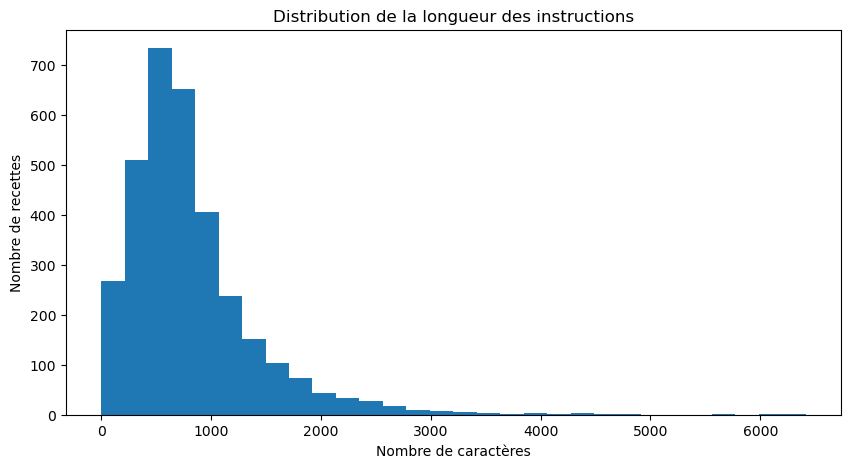

In [24]:
#13. Visualiser la longueur des instructions
#Nous allons représenter graphiquement la distribution de la longueur des instructions.


plt.figure(figsize=(10, 5))

plt.hist(data_clean['Instruction_Length'], bins=30)

plt.title("Distribution de la longueur des instructions")
plt.xlabel("Nombre de caractères")
plt.ylabel("Nombre de recettes")

plt.show()


In [25]:
#14. Identifier les instructions vides
#Nous allons vérifier combien de recettes ne possèdent pas d'instructions.


empty_instructions = (data_clean['Instructions'] == '').sum()

print("Nombre de recettes sans instructions :", empty_instructions)


Nombre de recettes sans instructions : 7


In [27]:
#15. Supprimer les recettes sans instructions


data_clean = data_clean[
    data_clean['Instructions'] != ''
].copy()

data_clean = data_clean.reset_index(drop=True)

print("Nombre de recettes restantes :", len(data_clean))


Nombre de recettes restantes : 3291


In [28]:
#16. Afficher le dataset nettoyé

data_clean[['Recipe_Name', 'Description', 'Instructions']].head()


,Recipe_Name,Description,Instructions
0,Duck and prune tagine,Duck legs are the ultimate choice for low-and-...,['Pour the oil into a heavy-based pan or casse...
1,Potato tagine with baked halloumi,This North African-inspired potato dish is by ...,['Heat the oven to 180°C fan/gas 6. Heat the o...
2,Merguez sausages with crispy chickpeas and pre...,"Merguez sausages with crispy, roasted chickpea...",['Heat the oven to 180°C fan/gas 6. Put the ch...
3,Chicken tagine casserole,Enjoy all the rich flavours of a chicken tagin...,['Heat the oven to 180ºC fan/gas 6. Slash the ...
4,Preserved lemons,With only two basic ingredients and some imagi...,['Juice 4 of the lemons and set the juice asid...


In [30]:
#17. Enregistrer le dataset nettoyé


data_clean.to_csv(
    "../Dataset_ProjetIA_food/moroccan_recipes_cleaned.csv",
    index=False,
    encoding='utf-8-sig'
)

print("Dataset nettoyé enregistré avec succès !")


Dataset nettoyé enregistré avec succès !


In [34]:

clean_data = pd.read_csv("../Dataset_ProjetIA_food/moroccan_recipes_cleaned.csv")

print("Dimensions :", clean_data.shape)
print("\nColonnes :", clean_data.columns.tolist())

clean_data.head()


Dimensions : (3291, 6)

Colonnes : ['prompt', 'completion', 'Recipe_Name', 'Description', 'Instructions', 'Instruction_Length']


,prompt,completion,Recipe_Name,Description,Instructions,Instruction_Length
0,Recipe Name : Duck and prune tagine\n Descript...,['Pour the oil into a heavy-based pan or casse...,Duck and prune tagine,Duck legs are the ultimate choice for low-and-...,['Pour the oil into a heavy-based pan or casse...,948
1,Recipe Name : Potato tagine with baked halloum...,['Heat the oven to 180°C fan/gas 6. Heat the o...,Potato tagine with baked halloumi,This North African-inspired potato dish is by ...,['Heat the oven to 180°C fan/gas 6. Heat the o...,737
2,Recipe Name : Merguez sausages with crispy chi...,['Heat the oven to 180°C fan/gas 6. Put the ch...,Merguez sausages with crispy chickpeas and pre...,"Merguez sausages with crispy, roasted chickpea...",['Heat the oven to 180°C fan/gas 6. Put the ch...,904
3,Recipe Name : Chicken tagine casserole\n Descr...,['Heat the oven to 180ºC fan/gas 6. Slash the ...,Chicken tagine casserole,Enjoy all the rich flavours of a chicken tagin...,['Heat the oven to 180ºC fan/gas 6. Slash the ...,486
4,Recipe Name : Preserved lemons\n Description :...,['Juice 4 of the lemons and set the juice asid...,Preserved lemons,With only two basic ingredients and some imagi...,['Juice 4 of the lemons and set the juice asid...,828
